In [2]:
# ==================================
# IMPORTS
# ==================================
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parents[1]

sys.path.insert(
    0,
    str(PROJECT_ROOT)
)

import torch
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from core.fno import FNO1d
from flow.poiseuille.dataset import PoiseuilleDataset
from flow.poiseuille.solver import solve_poiseuille

In [3]:
# ==================================
# DEVICE
# ==================================

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using:", device)

Using: mps


In [ ]:
# ==================================
# LOAD CHECKPOINT
# ==================================

checkpoint = torch.load(
    "checkpoints/best_fno.pt",
    map_location=device
)

print("Checkpoint Loaded...")

In [6]:
# ==================================
# LOAD MODEL
# ==================================

model = FNO1d(
    modes=checkpoint["modes"],
    width=checkpoint["width"],
    in_channels=checkpoint["in_channels"],
    out_channels=checkpoint["out_channels"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Model Loaded...")

Model Loaded...


In [7]:
# ==================================
# LOAD DATASET
# ==================================

dataset = PoiseuilleDataset(
    "data/poiseuille_dataset_20.pt"
)

print("Dataset Loaded...")

Dataset Loaded...


In [8]:
# ==================================
# PARAMETERS
# ==================================

nu = 0.01
G = 1.0

N_FRAMES = 2000

In [9]:
# ==================================
# GROUND TRUTH
# ==================================

solver_snapshots = solve_poiseuille(
    nu=nu,
    G=G,
    verbose=False
)

solver_snapshots = torch.stack(
    solver_snapshots
)

indices = torch.linspace(
    0,
    len(solver_snapshots)-1,
    N_FRAMES,
    dtype=torch.long
)

solver_snapshots = solver_snapshots[
    indices
]

solver_snapshots = solver_snapshots.to(
    device
)

print(
    "Ground Truth Frames:",
    len(solver_snapshots)
)

Ground Truth Frames: 2000


In [10]:
# ==================================
# AUTOREGRESSIVE ROLLOUT
# ==================================

u0 = torch.zeros_like(
    dataset.y,
    device=device
)

current = (
    u0 - checkpoint["X_mean"].to(device)
) / checkpoint["X_std"].to(device)

nu_norm = (
    nu - checkpoint["nu_mean"].item()
) / checkpoint["nu_std"].item()

G_norm = (
    G - checkpoint["G_mean"].item()
) / checkpoint["G_std"].item()

y_gpu = dataset.y.to(device)

pred_frames = []

print("Generating rollout...")

with torch.no_grad():

    for _ in range(N_FRAMES):

        nu_channel = (
            torch.ones_like(y_gpu)
            * nu_norm
        )

        G_channel = (
            torch.ones_like(y_gpu)
            * G_norm
        )

        inp = torch.stack(
            [
                current,
                y_gpu,
                nu_channel,
                G_channel
            ],
            dim=0
        )

        inp = inp.unsqueeze(0)

        pred = model(inp)

        current = pred.squeeze()

        current_phys = (
            current
            * checkpoint["Y_std"].to(device)
            + checkpoint["Y_mean"].to(device)
        )

        pred_frames.append(
            current_phys.clone()
        )

print("Rollout Complete...")

Generating rollout...
Rollout Complete...


In [11]:
print(torch.isnan(pred_frames[-1]).any())
print(torch.isinf(pred_frames[-1]).any())

print(pred_frames[-1].min())
print(pred_frames[-1].max())

tensor(False, device='cuda:0')
tensor(False, device='cuda:0')
tensor(0.0121, device='cuda:0')
tensor(1.1470, device='cuda:0')


In [12]:
# ==================================
# PARTICLE FLOW ANIMATION
# ==================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# ----------------------------------
# particles
# ----------------------------------

N_PARTICLES_Y = 25

y_particles = torch.linspace(
    0.02,
    0.98,
    N_PARTICLES_Y,
    device=device
)

# initial x positions
N_X = 15

x_grid, y_grid = torch.meshgrid(
    torch.linspace(0, 1, N_X, device=device),
    torch.linspace(
        0.02,
        0.98,
        N_PARTICLES_Y,
        device=device
    ),
    indexing="xy"
)

x_particles = x_grid.flatten()
y_particles = y_grid.flatten()

# store trajectory

trajectory = []

trajectory.append(
    x_particles.clone()
)

# ----------------------------------
# integrate particle motion
# ----------------------------------

dx_scale = 0.05

for velocity_profile in pred_frames:

    # interpolate velocity onto particle locations

    indices = (
        y_particles
        * (len(dataset.y)-1)
    ).long()

    particle_velocity = velocity_profile[
        indices
    ]

    x_particles = (
        x_particles
        + dx_scale * particle_velocity
    )

    trajectory.append(
        x_particles.clone()
    )

trajectory = torch.stack(
    trajectory
)

print(
    "Trajectory shape:",
    trajectory.shape
)

Trajectory shape: torch.Size([2001, 375])


Animation size has reached 20989587 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


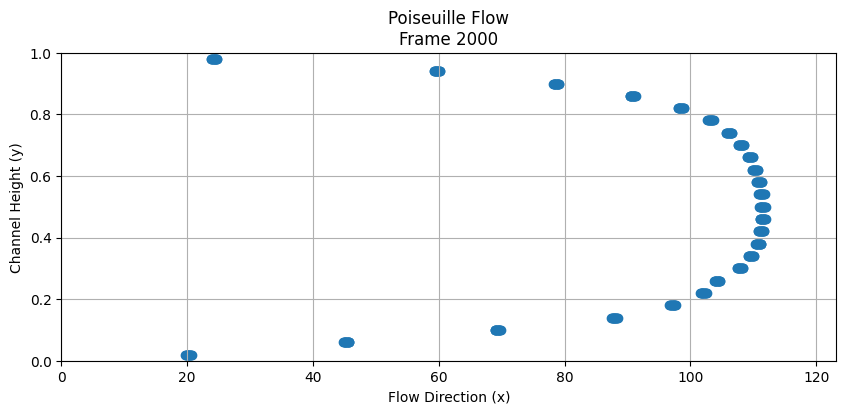

In [ ]:
# ==================================
# ANIMATE PARTICLES
# ==================================

fig, ax = plt.subplots(
    figsize=(10,4)
)

scatter = ax.scatter(
    [],
    []
)

ax.set_xlim(
    0,
    trajectory.max().cpu().item()*1.1
)

ax.set_ylim(
    0,
    1
)

ax.set_xlabel("Flow Direction (x)")
ax.set_ylabel("Channel Height (y)")

ax.set_title(
    "Poiseuille Flow Particle Advection"
)

ax.grid(True)

def update(frame):

    scatter.set_offsets(
        np.column_stack(
            [
                trajectory[frame].cpu().numpy(),
                y_particles.cpu().numpy()
            ]
        )
    )

    ax.set_title(
        f"Poiseuille Flow\nFrame {frame}"
    )

    return scatter,

ani = FuncAnimation(
    fig,
    update,
    frames=len(trajectory),
    interval=50,
    blit=True
)

# save
ani.save(
    "poiseuille_fno.mp4",
    fps = 30,
    writer = "ffmpeg"
)

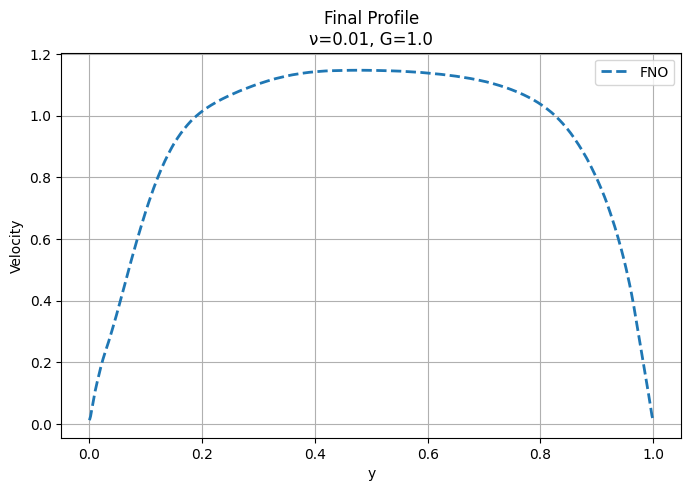

In [15]:
# ==================================
# FINAL PROFILE
# ==================================

plt.figure(figsize=(8,5))

# plt.plot(
#     dataset.y.cpu(),
#     solver_snapshots[-1].cpu(),
#     linewidth=3,
#     label="Ground Truth"
# )

plt.plot(
    dataset.y.cpu(),
    pred_frames[-1].cpu(),
    "--",
    linewidth=2,
    label="FNO"
)

plt.xlabel("y")
plt.ylabel("Velocity")

plt.title(
    f"Final Profile\nν={nu}, G={G}"
)

plt.grid(True)
plt.legend()

plt.show()